In [1]:
# Joseph Black
# Code for the paper: An Audit of Evaluation and Reporting Practice on the CMU Keystroke Dynamics Benchmark
# November 10, 2026

# Keystroke dynamics authentication against policy operating points

Data: the CMU Keystroke Dynamics Benchmark (Killourhy and Maxion, 2009). 51 subjects typed the password `.tie5Roanl` 400 times each across 8 sessions. Each repetition is one row of 31 timing features. Downloaded from the authors' page at Carnegie Mellon University.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, cross_val_predict, StratifiedKFold
from sklearn.metrics import confusion_matrix
from scipy.spatial.distance import pdist
from sklearn.svm import OneClassSVM
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split

## 1. Load and describe the data

In [3]:
# Load the CSV that sits beside this notebook
data = pd.read_csv("DSL-StrongPasswordData.csv")
data.head()

,subject,sessionIndex,rep,H.period,DD.period.t,UD.period.t,H.t,DD.t.i,UD.t.i,H.i,...,H.a,DD.a.n,UD.a.n,H.n,DD.n.l,UD.n.l,H.l,DD.l.Return,UD.l.Return,H.Return
0,s002,1,1,0.1491,0.3979,0.2488,0.1069,0.1674,0.0605,0.1169,...,0.1349,0.1484,0.0135,0.0932,0.3515,0.2583,0.1338,0.3509,0.2171,0.0742
1,s002,1,2,0.1111,0.3451,0.2340,0.0694,0.1283,0.0589,0.0908,...,0.1412,0.2558,0.1146,0.1146,0.2642,0.1496,0.0839,0.2756,0.1917,0.0747
2,s002,1,3,0.1328,0.2072,0.0744,0.0731,0.1291,0.0560,0.0821,...,0.1621,0.2332,0.0711,0.1172,0.2705,0.1533,0.1085,0.2847,0.1762,0.0945
3,s002,1,4,0.1291,0.2515,0.1224,0.1059,0.2495,0.1436,0.1040,...,0.1457,0.1629,0.0172,0.0866,0.2341,0.1475,0.0845,0.3232,0.2387,0.0813
4,s002,1,5,0.1249,0.2317,0.1068,0.0895,0.1676,0.0781,0.0903,...,0.1312,0.1582,0.0270,0.0884,0.2517,0.1633,0.0903,0.2517,0.1614,0.0818


In [4]:
# Shape, missing values, and rows per subject
print("rows and columns:", data.shape)
print("missing values:", data.isna().sum().sum())
print("subjects:", data["subject"].nunique())
print("rows per subject:", data["subject"].value_counts().min(), "to", data["subject"].value_counts().max())

rows and columns: (20400, 34)
missing values: 0
subjects: 51
rows per subject: 400 to 400


## 2. Feature families

Three families: hold time (H), down-down latency (DD), and up-down latency (UD). For any key pair, DD equals the hold of the first key plus UD, so the three are not independent.

In [5]:
# Group the feature columns by their prefix
features = [c for c in data.columns if c not in ["subject", "sessionIndex", "rep"]]
hold = [c for c in features if c.startswith("H.")]
down_down = [c for c in features if c.startswith("DD.")]
up_down = [c for c in features if c.startswith("UD.")]
print("features:", len(features), " H:", len(hold), " DD:", len(down_down), " UD:", len(up_down))

# Check the identity on one key pair
difference = (data["DD.period.t"] - (data["H.period"] + data["UD.period.t"])).abs().max()
print("largest difference between DD and H + UD for the first pair:", round(difference, 10))

features: 31  H: 11  DD: 10  UD: 10
largest difference between DD and H + UD for the first pair: 0.0


## 3. The evaluation split

Following Killourhy and Maxion: for each subject, the first 200 rows are training, the last 200 are genuine test samples, and the first 5 rows of every other subject are impostor test samples. Training uses only the enrolled subject.

In [6]:
subjects = sorted(data["subject"].unique())
split = {}

for s in subjects:
    own = data[data["subject"] == s].sort_values(["sessionIndex", "rep"])
    others = data[data["subject"] != s].sort_values(["subject", "sessionIndex", "rep"])
    split[s] = {
        "train": own.iloc[:200][features],
        "genuine": own.iloc[200:][features],
        "impostor": others.groupby("subject").head(5)[features],
    }

print("train:", len(split["s002"]["train"]), " genuine test:", len(split["s002"]["genuine"]), " impostor test:", len(split["s002"]["impostor"]))

train: 200  genuine test: 200  impostor test: 250


## 4. The detector: scaled Manhattan distance

Fit on the subject's training rows by taking each feature's mean and mean absolute deviation. Score a row as the sum over features of |value - mean| / MAD. A lower score means the row looks more like the enrolled subject.

In [7]:
# Fit returns the mean and MAD of the training rows
def fit(train):
    mean = train.mean()
    mad = (train - mean).abs().mean()
    return mean, mad

# Score every row of a frame against a fitted detector
def score(rows, mean, mad):
    return ((rows - mean).abs() / mad).sum(axis=1).values

## 5. Equal error rate per subject

Sweep thresholds across the genuine and impostor scores. At each threshold the false non-match rate is the share of genuine scores above it and the false match rate is the share of impostor scores at or below it. The EER is where the two are closest. The mean over 51 subjects should reproduce the published 0.096.

In [8]:
def equal_error_rate(genuine, impostor):
    best_gap = 1.0
    best_eer = 1.0
    for t in np.unique(np.concatenate([genuine, impostor])):
        fnmr = np.mean(genuine > t)
        fmr = np.mean(impostor <= t)
        if abs(fnmr - fmr) < best_gap:
            best_gap = abs(fnmr - fmr)
            best_eer = (fnmr + fmr) / 2
    return best_eer

In [9]:
# Score every subject's test sets and collect the EERs
eer = {}
genuine_scores = {}
impostor_scores = {}

for s in subjects:
    mean, mad = fit(split[s]["train"])
    genuine_scores[s] = score(split[s]["genuine"], mean, mad)
    impostor_scores[s] = score(split[s]["impostor"], mean, mad)
    eer[s] = equal_error_rate(genuine_scores[s], impostor_scores[s])

eer = pd.Series(eer, name="eer")
print("mean EER across 51 subjects:", round(eer.mean(), 4))
print("published value: 0.096")

mean EER across 51 subjects: 0.096
published value: 0.096


In [10]:
# All 51 subjects, best five and worst five
eer_sorted = eer.sort_values()
print("best five")
print(eer_sorted.head().round(4).to_string())
print()
print("worst five")
print(eer_sorted.tail().round(4).to_string())

best five
s036    0.0090
s055    0.0155
s052    0.0155
s043    0.0155
s012    0.0200

worst five
s035    0.1955
s002    0.2400
s032    0.2710
s031    0.2755
s047    0.3245


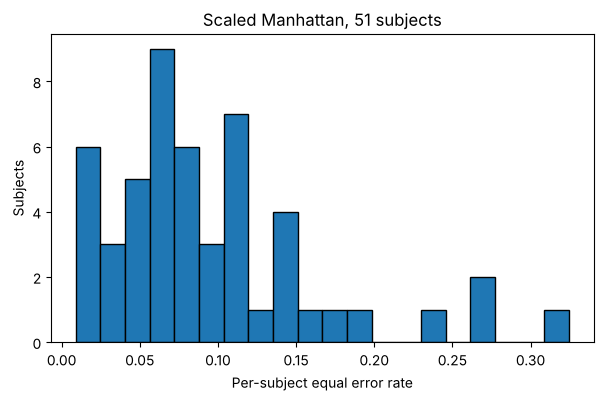

In [11]:
# Figure 1: distribution of per-subject EER
plt.figure(figsize=(7, 4))
plt.hist(eer, bins=20, edgecolor="black")
plt.xlabel("Per-subject equal error rate")
plt.ylabel("Subjects")
plt.title("Scaled Manhattan, 51 subjects")
plt.show()

## 6. Two more original detectors and the zero-miss rate

Killourhy and Maxion paired the EER with a second operating point: the zero-miss false-alarm rate, the share of genuine attempts rejected when the threshold is set so that no impostor gets through. This section adds that metric and two more of their detectors, Outlier Count and the one-class support vector machine (SVM), so that the paper's Table 3 can be checked against code.

In [12]:
# Zero-miss false-alarm rate: reject every genuine score at or above the lowest impostor score
def zero_miss_rate(genuine, impostor):
    return np.mean(genuine >= impostor.min())

# Outlier Count: how many features fall more than 1.96 standard deviations from the training mean
def outlier_count(train, rows):
    mean = train.mean()
    sd = train.std()
    return ((rows - mean).abs() / sd > 1.96).sum(axis=1).values.astype(float)

# One-class SVM on standardized features, with the kernel width set from the median pairwise distance
# of the training rows (an approximation of the R defaults the original authors used)
def one_class_svm(train, rows):
    mean = train.mean()
    sd = train.std()
    z_train = ((train - mean) / sd).values
    gamma = 1 / np.median(pdist(z_train, "sqeuclidean"))
    model = OneClassSVM(kernel="rbf", nu=0.5, gamma=gamma).fit(z_train)
    return -model.decision_function(((rows - mean) / sd).values)

In [13]:
# Run all three detectors for every subject; keep the scores for the global-threshold check
def scaled_manhattan(train, rows):
    mean, mad = fit(train)
    return score(rows, mean, mad)

detectors = {"Scaled Manhattan": scaled_manhattan,
             "Outlier Count": outlier_count,
             "One-class SVM": one_class_svm}
rows = []
all_scores = {name: {"genuine": [], "impostor": []} for name in detectors}
for s in subjects:
    for name, detector in detectors.items():
        g = detector(split[s]["train"], split[s]["genuine"])
        i = detector(split[s]["train"], split[s]["impostor"])
        rows.append({"subject": s, "detector": name,
                     "eer": equal_error_rate(g, i), "zero_miss": zero_miss_rate(g, i)})
        all_scores[name]["genuine"].append(g)
        all_scores[name]["impostor"].append(i)
by_detector = pd.DataFrame(rows)

# Mean and standard deviation across the 51 subjects
print(by_detector.groupby("detector")[["eer", "zero_miss"]].agg(["mean", "std"]).round(3))
print()
print("published: Scaled Manhattan 0.096 / 0.601, Outlier Count 0.102 / 0.782, One-class SVM 0.102 / 0.504")

                    eer        zero_miss       
                   mean    std      mean    std
detector                                       
One-class SVM     0.104  0.066     0.517  0.322
Outlier Count     0.101  0.077     0.782  0.306
Scaled Manhattan  0.096  0.069     0.601  0.337

published: Scaled Manhattan 0.096 / 0.601, Outlier Count 0.102 / 0.782, One-class SVM 0.102 / 0.504


In [14]:
# How many subjects would have more than 90 percent of their own attempts rejected at zero-miss
print((by_detector["zero_miss"] > 0.9).groupby(by_detector["detector"]).sum().to_string())
print()
# Spread of Scaled Manhattan EER across subjects, and the share carried by the worst five
r = by_detector[by_detector["detector"] == "Scaled Manhattan"]["eer"]
print("range:", round(r.min(), 3), "to", round(r.max(), 3), " median:", round(r.median(), 3))
print("worst five subjects' share of summed EER:", round(r.nlargest(5).sum() / r.sum(), 2))

detector
One-class SVM        7
Outlier Count       30
Scaled Manhattan    10

range: 0.009 to 0.324  median: 0.08
worst five subjects' share of summed EER: 0.27


## 7. One global threshold for all subjects

The per-subject EER picks each subject's threshold after seeing that subject's impostor scores. A deployed system cannot do that, so pool every subject's raw scores and compute the EER and zero-miss rate under a single threshold.

In [15]:
# Pool raw scores across subjects and evaluate them under one threshold
for name in detectors:
    g = np.concatenate(all_scores[name]["genuine"])
    i = np.concatenate(all_scores[name]["impostor"])
    print(name, " global EER:", round(equal_error_rate(g, i), 3), " global zero-miss:", round(zero_miss_rate(g, i), 3))

Scaled Manhattan  global EER: 0.114  global zero-miss: 0.989
Outlier Count  global EER: 0.113  global zero-miss: 1.0


One-class SVM  global EER: 0.12  global zero-miss: 0.984


## 8. Fixed threshold chosen from enrollment data

NIST SP 800-63B-4 (Section 3.2.3.1) says a biometric system SHALL be configured with a fixed threshold, SHALL operate with a false match rate of 1 in 10,000 or better under zero-effort impostor attempts, and SHOULD demonstrate a false non-match rate under 5 percent.

A deployed system has to choose that threshold before it sees any test attempts, so the threshold here comes from enrollment data only. For each subject, the detector is fit on the first 150 training rows and scores the remaining 50 training rows (151 to 200) as a calibration set. Each subject's scores are standardised by the mean and standard deviation of that subject's own calibration scores, the calibration scores of all subjects are pooled, and the one threshold where 5 percent of them sit above it is chosen. The false non-match rate and false match rate are then read on the untouched test set: rows 201 to 400 and the first 5 rows of every other subject. The next cell repeats the procedure without the standardisation.

In [16]:
# Fit on rows 1 to 150, calibrate on rows 151 to 200, then test on the original test set
cal_pooled = []
z_genuine = {}
z_impostor = {}

for s in subjects:
    train150 = split[s]["train"].iloc[:150]
    calibration = split[s]["train"].iloc[150:]
    mean, mad = fit(train150)
    cal_scores = score(calibration, mean, mad)
    m = cal_scores.mean()
    sd = cal_scores.std()
    cal_pooled.extend((cal_scores - m) / sd)
    z_genuine[s] = (score(split[s]["genuine"], mean, mad) - m) / sd
    z_impostor[s] = (score(split[s]["impostor"], mean, mad) - m) / sd

pooled_genuine = np.concatenate([z_genuine[s] for s in subjects])
pooled_impostor = np.concatenate([z_impostor[s] for s in subjects])

# The threshold where 5 percent of calibration scores sit above it, chosen before any test data is seen
threshold = np.quantile(cal_pooled, 0.95)
fnmr_fixed = np.mean(pooled_genuine > threshold)
fmr_fixed = np.mean(pooled_impostor <= threshold)

nist_limit = 1 / 10000
print("fixed threshold:", round(threshold, 3))
print("false non-match rate on test:", round(fnmr_fixed, 4), " (target: under 0.05)")
print("false match rate on test:", round(fmr_fixed, 4))
print("NIST limit:", nist_limit)
print("times the limit:", round(fmr_fixed / nist_limit))

fixed threshold: 1.926
false non-match rate on test: 0.0934  (target: under 0.05)
false match rate on test: 0.1793
NIST limit: 0.0001
times the limit: 1793


In [17]:
# Check: the same procedure without standardising, so one threshold on raw scores
raw_cal, raw_genuine, raw_impostor = [], [], []
for s in subjects:
    mean, mad = fit(split[s]["train"].iloc[:150])
    raw_cal.extend(score(split[s]["train"].iloc[150:], mean, mad))
    raw_genuine.extend(score(split[s]["genuine"], mean, mad))
    raw_impostor.extend(score(split[s]["impostor"], mean, mad))
raw_threshold = np.quantile(raw_cal, 0.95)
print("false non-match rate on test:", round(np.mean(np.array(raw_genuine) > raw_threshold), 4))
print("false match rate on test:", round(np.mean(np.array(raw_impostor) <= raw_threshold), 4))

false non-match rate on test: 0.0744
false match rate on test: 0.1935


## 9. Measurement resolution of the benchmark

Each subject faces 250 impostor attempts, so the smallest observable false match rate per subject is 1 in 250. By the rule of three, demonstrating a rate of p with 95 percent confidence needs about 3/p attempts with no false matches observed.

In [18]:
attempts_per_subject = len(split["s002"]["impostor"])
attempts_total = attempts_per_subject * len(subjects)
print("impostor attempts per subject:", attempts_per_subject)
print("smallest observable FMR per subject:", round(1 / attempts_per_subject, 4))
print("attempts needed to demonstrate 1 in 10,000:", int(3 / nist_limit))
print("attempts the benchmark has in total:", attempts_total)

impostor attempts per subject: 250
smallest observable FMR per subject: 0.004
attempts needed to demonstrate 1 in 10,000: 30000
attempts the benchmark has in total: 12750


## 10. Per-subject results at the fixed threshold
Each subject’s own false match rate at the single pooled threshold, and how that compares with the per-subject EER ranking.

In [19]:
# Each subject's own false match rate at the one pooled threshold
fmr_at_fixed = {}
for s in subjects:
    fmr_at_fixed[s] = np.mean(z_impostor[s] <= threshold)
fmr_at_fixed = pd.Series(fmr_at_fixed, name="fmr_fixed")

print("worst five at the fixed threshold")
print(fmr_at_fixed.sort_values().tail().round(3).to_string())
print()
print("worst subject under per-subject EER:", eer.idxmax())
print("worst subject under the fixed threshold:", fmr_at_fixed.idxmax())

worst five at the fixed threshold
s032    0.472
s031    0.516
s038    0.532
s047    0.540
s016    0.584

worst subject under per-subject EER: s047
worst subject under the fixed threshold: s016


In [20]:
# How exposure spreads at the fixed threshold, and where the most exposed subject sits under per-subject EER
print("subjects with no false matches:", (fmr_at_fixed == 0).sum())
print("subjects accepting half or more of impostor attempts:", (fmr_at_fixed >= 0.5).sum())
print("median subject's false match rate:", round(fmr_at_fixed.median(), 3))
worst = fmr_at_fixed.idxmax()
print(worst, "per-subject EER:", round(eer[worst], 4), " subjects with a worse EER:", (eer > eer[worst]).sum())

subjects with no false matches: 3
subjects accepting half or more of impostor attempts: 4
median subject's false match rate: 0.116
s016 per-subject EER: 0.18  subjects with a worse EER: 5


## 11. Identification

The multi-class view: given a row, which of the 51 subjects typed it. Random forest with five-fold cross-validation, then a confusion matrix from cross-validated predictions.

In [21]:
X = data[features]
y = data["subject"]
forest = RandomForestClassifier(n_estimators=100, random_state=42)
# Shuffled folds, since the rows are sorted by subject and session
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

accuracy = cross_val_score(forest, X, y, cv=folds)
print("five-fold accuracy:", round(accuracy.mean(), 4))
print("chance:", round(1 / len(subjects), 4))

five-fold accuracy: 0.9316
chance: 0.0196


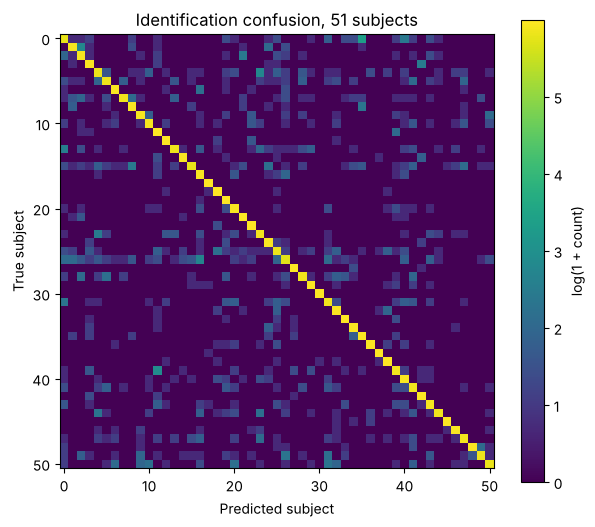

In [22]:
# Confusion matrix from predictions made on held-out folds
predicted = cross_val_predict(forest, X, y, cv=folds)
matrix = confusion_matrix(y, predicted, labels=subjects)

# Figure 2: the matrix on a log scale so the off-diagonal shows
plt.figure(figsize=(7, 6))
plt.imshow(np.log1p(matrix), cmap="viridis")
plt.colorbar(label="log(1 + count)")
plt.xlabel("Predicted subject")
plt.ylabel("True subject")
plt.title("Identification confusion, 51 subjects")
plt.show()

In [23]:
# For each subject, how many rows of other subjects were predicted as them
off_diagonal = matrix.copy()
np.fill_diagonal(off_diagonal, 0)
incoming = pd.Series(off_diagonal.sum(axis=0), index=subjects, name="incoming")
print("most often mistaken for")
print(incoming.sort_values().tail().to_string())

most often mistaken for
s048    51
s031    52
s016    52
s021    56
s002    67


## 12. Correlates of per-subject error

Two per-subject measures. Variability is computed from the subject's 200 training rows only, so it is something a system could measure at enrollment: take each feature's standard deviation over those rows, divide it by that feature's mean absolute deviation across the whole dataset so the features are on a common scale, and average over the 31 features. Incoming is the count from section 11. Both are correlated with per-subject EER and with the false match rate at the fixed threshold.

In [24]:
# Variability from the training rows only, with each feature scaled by its population spread
population_mad = (data[features] - data[features].mean()).abs().mean()
variability = {}
for s in subjects:
    variability[s] = (split[s]["train"].std() / population_mad).mean()
variability = pd.Series(variability, name="variability")

In [25]:
# One table and the rank correlations
table = pd.concat([eer, fmr_at_fixed, variability, incoming], axis=1)
correlations = table.corr(method="spearman")
print(correlations.loc[["variability", "incoming"], ["eer", "fmr_fixed"]].round(3).to_string())

               eer  fmr_fixed
variability  0.300      0.394
incoming     0.534      0.520


In [26]:
# Significance of the rank correlations
from scipy.stats import spearmanr
for a in ["variability", "incoming"]:
    for b in ["eer", "fmr_fixed"]:
        rho, p = spearmanr(table[a], table[b])
        print(a, "vs", b, " rho:", round(rho, 3), " p:", round(p, 4))

variability vs eer  rho: 0.3  p: 0.0326
variability vs fmr_fixed  rho: 0.394  p: 0.0043
incoming vs eer  rho: 0.534  p: 0.0001
incoming vs fmr_fixed  rho: 0.52  p: 0.0001


In [27]:
# How closely per-subject EER tracks exposure at the fixed threshold
rho, p = spearmanr(table["eer"], table["fmr_fixed"])
print("eer vs fmr_fixed  rho:", round(rho, 3), " p:", round(p, 6))
worst_eer = set(table["eer"].nlargest(5).index)
worst_fmr = set(table["fmr_fixed"].nlargest(5).index)
print("overlap of the five worst by each measure:", sorted(worst_eer & worst_fmr))

eer vs fmr_fixed  rho: 0.771  p: 0.0
overlap of the five worst by each measure: ['s031', 's032', 's047']


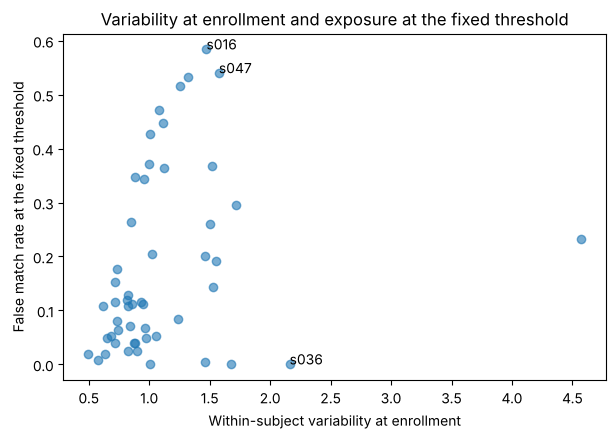

In [28]:
# Figure 3: variability against false match rate at the fixed threshold
plt.figure(figsize=(7, 4.5))
plt.scatter(table["variability"], table["fmr_fixed"], alpha=0.6)
for s in [eer.idxmin(), eer.idxmax(), fmr_at_fixed.idxmax()]:
    plt.annotate(s, (table.loc[s, "variability"], table.loc[s, "fmr_fixed"]))
plt.xlabel("Within-subject variability at enrollment")
plt.ylabel("False match rate at the fixed threshold")
plt.title("Variability at enrollment and exposure at the fixed threshold")
plt.show()

## 13. Effect of protocol changes, one factor at a time

Several later studies trained on rows from the other subjects, the same subjects later used as impostors, and some also shuffled each subject's rows before splitting, which mixes sessions between training and test. To separate those two changes, train a default HistGradientBoosting classifier per subject under four setups that each change one thing:

(a) sessions kept in order (train on rows 1 to 200, test on 201 to 400), with impostor negatives from other subjects but never from the impostors being tested;
(b) sessions kept in order, with the tested impostors' later rows allowed in training;
(c) the genuine rows shuffled and split in half, so sessions are mixed, with impostors seen as in (b);
(d) the setup in the style of Ibrahim et al. (2023): all 400 genuine rows plus 8 random rows from each other subject, shuffled and split 70/30.

In (a) to (c) the negatives are 8 random rows per subject from row 6 onward, so they never include the first five rows used as impostor test attempts.

In [29]:
# Helpers: 8 random rows from row 6 onward for each listed subject, and one fitted model's EER
rows_by_subject = {s: data[data["subject"] == s].sort_values(["sessionIndex", "rep"])[features] for s in subjects}

def negatives(subject_list, rng):
    return np.vstack([rows_by_subject[t].iloc[5:].sample(8, random_state=int(rng.integers(1e9))).values
                      for t in subject_list])

def model_eer(genuine_train, negative_train, genuine_test, impostor_test):
    X = np.r_[genuine_train, negative_train]
    y = np.r_[np.zeros(len(genuine_train)), np.ones(len(negative_train))]
    model = HistGradientBoostingClassifier(random_state=0).fit(X, y)
    return equal_error_rate(model.predict_proba(genuine_test)[:, 1], model.predict_proba(impostor_test)[:, 1])

rng = np.random.default_rng(42)
ladder = {"a": [], "b": [], "c": []}
for s in subjects:
    own = rows_by_subject[s].values
    others = [t for t in subjects if t != s]
    impostor_test = np.vstack([rows_by_subject[t].iloc[:5].values for t in others])

    # (a) impostors never seen: five groups of 10 impostors, each tested by a model trained without them
    group_eers = []
    for group in np.array_split(np.array(others), 5):
        rest = [t for t in others if t not in group]
        group_test = np.vstack([rows_by_subject[t].iloc[:5].values for t in group])
        group_eers.append(model_eer(own[:200], negatives(rest, rng), own[200:], group_test))
    ladder["a"].append(np.mean(group_eers))

    # (b) tested impostors' later rows allowed in training, sessions still in order
    ladder["b"].append(model_eer(own[:200], negatives(others, rng), own[200:], impostor_test))

    # (c) genuine rows shuffled before a half split, so sessions are mixed
    g_train, g_test = train_test_split(own, test_size=0.5, random_state=0)
    ladder["c"].append(model_eer(g_train, negatives(others, rng), g_test, impostor_test))

for k, label in [("a", "(a) sessions in order, impostors unseen"),
                 ("b", "(b) sessions in order, impostors seen"),
                 ("c", "(c) sessions mixed, impostors seen")]:
    print(label, " mean EER:", round(np.mean(ladder[k]), 3), " SD:", round(np.std(ladder[k], ddof=1), 3))

(a) sessions in order, impostors unseen  mean EER: 0.09  SD: 0.083
(b) sessions in order, impostors seen  mean EER: 0.086  SD: 0.082
(c) sessions mixed, impostors seen  mean EER: 0.031  SD: 0.022


In [30]:
# (d) In the style of Ibrahim et al.: all rows shuffled and split 70/30
rng = np.random.default_rng(42)
changed = []
for s in subjects:
    genuine = data[data["subject"] == s][features].values
    others = data[data["subject"] != s]
    impostors = others.groupby("subject", group_keys=False).apply(
        lambda d: d.sample(8, random_state=int(rng.integers(1e9))))[features].values
    X = np.r_[genuine, impostors]
    y = np.r_[np.zeros(len(genuine)), np.ones(len(impostors))]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)
    model = HistGradientBoostingClassifier(random_state=0).fit(X_train, y_train)
    p = model.predict_proba(X_test)[:, 1]
    changed.append(equal_error_rate(p[y_test == 0], p[y_test == 1]))
changed = pd.Series(changed, index=subjects)
print("(d) all rows shuffled 70/30  mean EER:", round(changed.mean(), 3), " SD:", round(changed.std(), 3))
print("one-class Scaled Manhattan under the original protocol:", round(eer.mean(), 3))

(d) all rows shuffled 70/30  mean EER: 0.025  SD: 0.02
one-class Scaled Manhattan under the original protocol: 0.096


## 14. Export

In [31]:
table.round(4).to_csv("per_subject_results.csv")
correlations.round(4).to_csv("correlations.csv")
print("written per_subject_results.csv and correlations.csv")

written per_subject_results.csv and correlations.csv
